# 01webterrain: seabed and land for the first web page

PF9, step 2. Turns `data/bering_ibcao_laea_200m.tif` (from 00bathymetry) into three files for the deck.gl TerrainLayer page:

1. `docs/data/bering_height.png`: heights packed into the red, green and blue of each pixel (decoded by the page),
2. `docs/data/bering_texture.png`: the colour picture draped on the terrain (seabed in sand and silt tones, land in greys and greens, with shading),
3. `docs/data/bering_meta.json`: where the picture sits, the exaggeration used, and the place labels.

**The flat local map trick.** deck.gl expects longitude and latitude. Our grid is in metres on a local map centred on the strait (67°N, 169°W). We give the page "fake" coordinates near 0°N 0°E, where web maps have almost no stretching, so 1 m on our grid is 1 m on the page. The 180° meridian never appears. The MapLibre version with a real basemap comes later.

**Two exaggerations.** The seabed is very flat (a few tens of metres) and the land is high (up to about 2000 m). One exaggeration cannot show both, so the heights are baked with one factor below sea level and another above. The page will say so.

## Section 0. Settings

Lines marked `# <-` can be changed. `VISUAL:` settings only change pictures.

In [1]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
IN_FILE = PROJECT_DIR / "data" / "bering_ibcao_laea_200m.tif"
WEB_DIR = PROJECT_DIR / "docs" / "data"
FIG_DIR = PROJECT_DIR / "figures"

LOCAL_CRS = "+proj=laea +lat_0=67 +lon_0=-169 +datum=WGS84 +units=m +no_defs"  # <- must match 00bathymetry

HEIGHT_RES_M = 1000  # <- cell size of the height image in metres (1000 gives about 1450 x 960 pixels)
TEXTURE_RES_M = 500  # <- cell size of the colour picture in metres (500 gives about 2900 x 1930 pixels)

SEABED_EXAG = 40  # <- VISUAL: vertical exaggeration below sea level
LAND_EXAG = 4  # <- VISUAL: vertical exaggeration above sea level
DEEP_LIMIT_M = -300  # <- VISUAL: water deeper than this is drawn at this depth (only the Arctic slope corner)

SUN_AZIMUTH = 315  # <- VISUAL: light from the northwest
SUN_ALTITUDE = 35  # <- VISUAL: sun height in degrees
SHADE_STRENGTH = 0.5  # <- VISUAL: 0 = no shading, 1 = strong shading

SEABED_COLOURS = ["#e6d3a8", "#c9b07c", "#9c8457", "#6b5a3d", "#3f3628"]  # <- VISUAL: sand at 0 m to dark silt at the deep limit
LAND_COLOURS = ["#cfcbb5", "#a3a98a", "#76805f", "#8f8a7c", "#f2f2f2"]  # <- VISUAL: coast to mountain tops

PLACES = []  # <- labels for the page (lat, lon in degrees; west is negative); one line per place
PLACES.append({"name": "Cape Dezhnev", "lat": 66.08, "lon": -169.65, "kind": "cape"})
PLACES.append({"name": "Cape Prince of Wales", "lat": 65.64, "lon": -168.09, "kind": "cape"})
PLACES.append({"name": "Big Diomede (Russia)", "lat": 65.78, "lon": -169.06, "kind": "island"})
PLACES.append({"name": "Little Diomede (USA)", "lat": 65.75, "lon": -168.93, "kind": "island"})
PLACES.append({"name": "Wrangel Island", "lat": 71.25, "lon": -179.8, "kind": "island"})
PLACES.append({"name": "Herald Island", "lat": 71.38, "lon": -175.68, "kind": "island"})
PLACES.append({"name": "Point Hope", "lat": 68.35, "lon": -166.80, "kind": "town"})
PLACES.append({"name": "Utqiagvik (Barrow)", "lat": 71.29, "lon": -156.79, "kind": "town"})
PLACES.append({"name": "Kotzebue", "lat": 66.90, "lon": -162.60, "kind": "town"})
PLACES.append({"name": "Nome", "lat": 64.50, "lon": -165.41, "kind": "town"})
PLACES.append({"name": "Uelen", "lat": 66.16, "lon": -169.81, "kind": "town"})
PLACES.append({"name": "Chukchi Sea", "lat": 69.6, "lon": -170.5, "kind": "sea"})
PLACES.append({"name": "Bering Sea", "lat": 64.4, "lon": -170.8, "kind": "sea"})
PLACES.append({"name": "Chukotka (Russia)", "lat": 66.6, "lon": -176.5, "kind": "region"})
PLACES.append({"name": "Alaska (USA)", "lat": 67.3, "lon": -158.5, "kind": "region"})

## Section 1. Libraries

In [2]:
import json
import numpy as np
import rasterio
from rasterio.enums import Resampling
from pyproj import Transformer
from PIL import Image
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

WEB_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)
EARTH_R = 6378137.0

## Section 2. Read the seabed at the two cell sizes

Averaging (not picking every nth cell) keeps narrow channels and small islands fair.

In [3]:
with rasterio.open(IN_FILE) as src:
    full_w = src.width
    full_h = src.height
    bounds = src.bounds
    in_res = src.res[0]
    h_w = int(round(full_w * in_res / HEIGHT_RES_M))
    h_h = int(round(full_h * in_res / HEIGHT_RES_M))
    t_w = int(round(full_w * in_res / TEXTURE_RES_M))
    t_h = int(round(full_h * in_res / TEXTURE_RES_M))
    z_height = src.read(1, out_shape=(h_h, h_w), resampling=Resampling.average).astype("float64")
    z_tex = src.read(1, out_shape=(t_h, t_w), resampling=Resampling.average).astype("float64")

print("Input:", full_w, "x", full_h, "cells of", in_res, "m")
print("Height image:", h_w, "x", h_h)
print("Colour picture:", t_w, "x", t_h)
print("Local bounds (km):", round(bounds.left / 1000), round(bounds.bottom / 1000), round(bounds.right / 1000), round(bounds.top / 1000))
print("Missing cells in height image:", int(np.isnan(z_height).sum()))

Input: 7269 x 4818 cells of 200.0 m
Height image: 1454 x 964
Colour picture: 2908 x 1927
Local bounds (km): -774 -335 679 629
Missing cells in height image: 94388


## Section 3. Bake the exaggerated heights into an image

Encoding: height = (R x 65536 + G x 256 + B) x 0.1 - 100000 metres, so 0.1 m steps from -100 km to +1577 km. The page's TerrainLayer gets the matching `elevationDecoder`. Missing cells (the grey corners outside the IBCAO window) are set to 0 m and made fully transparent in the colour picture.

In [4]:
def bake(z):
    z = np.where(np.isnan(z), 0, z)
    z = np.maximum(z, DEEP_LIMIT_M)
    return np.where(z < 0, z * SEABED_EXAG, z * LAND_EXAG)


baked = bake(z_height)
code_int = np.round((baked + 100000) / 0.1).astype(np.int64)
rgb_h = np.stack([(code_int // 65536) % 256, (code_int // 256) % 256, code_int % 256], axis=-1).astype(np.uint8)
Image.fromarray(rgb_h, "RGB").save(WEB_DIR / "bering_height.png", optimize=True)

check = (rgb_h[..., 0].astype(np.int64) * 65536 + rgb_h[..., 1].astype(np.int64) * 256 + rgb_h[..., 2].astype(np.int64)) * 0.1 - 100000
print("Largest decoding error (m):", round(float(np.abs(check - baked).max()), 3))
print("Baked height range (m):", round(float(baked.min())), "to", round(float(baked.max())))
print("Saved bering_height.png", round((WEB_DIR / "bering_height.png").stat().st_size / 1e6, 2), "MB")

Largest decoding error (m): 0.05
Baked height range (m): -12000 to 7720
Saved bering_height.png 2.35 MB


## Section 4. The colour picture

Seabed colours run from sand (at 0 m) to dark silt (at the deep limit), so when the page lowers the sea, the newly dry seabed already looks like land. Shading uses the same two exaggerations as the heights, so light and shape agree.

In [5]:
def hillshade(z, cell, azimuth, altitude):
    gy, gx = np.gradient(z, cell)
    slope = np.pi / 2 - np.arctan(np.hypot(gx, gy))
    aspect = np.arctan2(-gx, gy)
    az = np.radians(azimuth)
    alt = np.radians(altitude)
    shade = np.sin(alt) * np.sin(slope) + np.cos(alt) * np.cos(slope) * np.cos(az - aspect)
    return np.clip(shade, 0, 1)


zt = np.where(np.isnan(z_tex), DEEP_LIMIT_M, np.maximum(z_tex, DEEP_LIMIT_M))
shade = hillshade(bake(z_tex), TEXTURE_RES_M, SUN_AZIMUTH, SUN_ALTITUDE)
seabed_cmap = LinearSegmentedColormap.from_list("seabed", SEABED_COLOURS)
land_cmap = LinearSegmentedColormap.from_list("land", LAND_COLOURS)
seabed_rgb = seabed_cmap(np.sqrt(np.clip(zt / DEEP_LIMIT_M, 0, 1)))[..., :3]
land_rgb = land_cmap(np.clip(zt / 1800, 0, 1))[..., :3]
rgb_t = np.where((zt < 0)[..., None], seabed_rgb, land_rgb)
rgb_t = rgb_t * (1 - SHADE_STRENGTH + SHADE_STRENGTH * 1.6 * shade[..., None])
rgb_t = np.clip(rgb_t, 0, 1)
alpha = np.where(np.isnan(z_tex), 0, 255).astype(np.uint8)
tex = np.dstack([(rgb_t * 255).round().astype(np.uint8), alpha])
Image.fromarray(tex, "RGBA").save(WEB_DIR / "bering_texture.png", optimize=True)
print("Transparent (missing) share of the picture:", round(float((alpha == 0).mean()) * 100, 1), "%")
print("Saved bering_texture.png", round((WEB_DIR / "bering_texture.png").stat().st_size / 1e6, 2), "MB")

Transparent (missing) share of the picture: 6.8 %
Saved bering_texture.png 7.24 MB


## Section 5. Fake coordinates and labels

Local metres (x, y) become fake longitude and latitude near 0°, 0° with the inverse web Mercator formula, so the page measures exactly our metres. Place labels go through the same two steps.

In [6]:
def to_fake(x, y):
    lon = np.degrees(np.asarray(x) / EARTH_R)
    lat = np.degrees(2 * np.arctan(np.exp(np.asarray(y) / EARTH_R)) - np.pi / 2)
    return lon, lat


to_local = Transformer.from_crs("EPSG:4326", LOCAL_CRS, always_xy=True)
west, south = to_fake(bounds.left, bounds.bottom)
east, north = to_fake(bounds.right, bounds.top)

labels = []
for p in PLACES:
    lx, ly = to_local.transform(p["lon"], p["lat"])
    fx, fy = to_fake(lx, ly)
    labels.append({"name": p["name"], "kind": p["kind"], "position": [round(float(fx), 6), round(float(fy), 6)], "real_lat": p["lat"], "real_lon": p["lon"]})

meta = {}
meta["bounds"] = [round(float(west), 6), round(float(south), 6), round(float(east), 6), round(float(north), 6)]
meta["local_crs"] = LOCAL_CRS
meta["local_bounds_m"] = [bounds.left, bounds.bottom, bounds.right, bounds.top]
meta["height_png"] = "bering_height.png"
meta["texture_png"] = "bering_texture.png"
meta["decoder"] = {"rScaler": 6553.6, "gScaler": 25.6, "bScaler": 0.1, "offset": -100000}
meta["seabed_exaggeration"] = SEABED_EXAG
meta["land_exaggeration"] = LAND_EXAG
meta["deep_limit_m"] = DEEP_LIMIT_M
meta["height_res_m"] = HEIGHT_RES_M
meta["texture_res_m"] = TEXTURE_RES_M
meta["source"] = "IBCAO 5.2 (2026), 200 m grid, averaged"
meta["labels"] = labels
with open(WEB_DIR / "bering_meta.json", "w", encoding="utf-8") as f:
    json.dump(meta, f, indent=1)
print("Fake bounds:", meta["bounds"])
print("Saved bering_meta.json with", len(labels), "labels")

Fake bounds: [-6.956554, -3.004385, 6.103154, 5.641266]
Saved bering_meta.json with 15 labels


## Section 6. Preview

The colour picture as it will be draped, with the label positions, to check that everything lines up before the page exists.

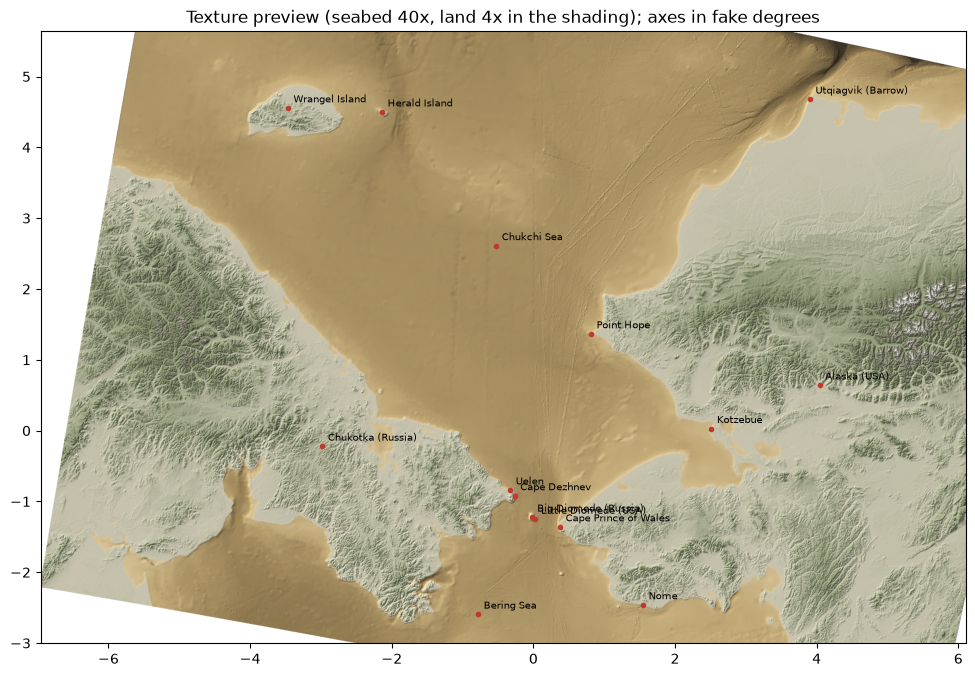

In [7]:
fig, ax = plt.subplots(figsize=(12, 12 * t_h / t_w))
ax.imshow(tex, extent=[west, east, south, north], origin="upper")
for lab in labels:
    ax.plot(*lab["position"], "o", color="#c0392b", markersize=3)
    ax.annotate(lab["name"], lab["position"], xytext=(4, 4), textcoords="offset points", fontsize=7)
ax.set_title(f"Texture preview (seabed {SEABED_EXAG}x, land {LAND_EXAG}x in the shading); axes in fake degrees")
fig.savefig(FIG_DIR / "01_texture_preview.png", dpi=120, bbox_inches="tight")
plt.show()

___
**END**